# 32 - Motor de alertas

| | |
|---|---|
| **Tarefa do plano** | S3-03 - risco (A) × água atual (B) × gatilhos (chuva anómala + caudal GloFAS) |
| **O que faz** | Define as regras de alerta, testa-as nos 20 anos e mostra o que está exposto em cada zona de risco |
| **Usa** | Séries diárias de chuva e caudal (notebooks 22 e 23), mapa do Modelo A, mapas do Modelo B, edifícios e equipamentos |
| **Produz** | `reports/semana_3/32_*.csv` (regras, episódios, exposição) e figuras |

**A lógica, em três perguntas**

| Pergunta | Quem responde | Com que frequência |
|---|---|---|
| **Quando** pode haver cheia? | Gatilhos: chuva acumulada e caudal do rio | todos os dias |
| **Onde**? | Modelo A: classes de suscetibilidade | fixo |
| **Quem** está exposto? | Edifícios, escolas e unidades de saúde em cada classe | fixo |
| A água chegou mesmo? | Modelo B: mapa de água por satélite | depois, por mês |

**Níveis**

| Nível | Chuva (7 dias, bacia) | Caudal em Marracuene |
|---|---|---|
| amarelo | entre os 5 % mais altos para a época | acima do percentil 90 |
| laranja | entre o 1 % mais alto para a época | acima do percentil 97 |
| vermelho | laranja na chuva **e** laranja no caudal | acima do percentil 99,5 |

O nível do dia é o mais alto dos dois gatilhos. A chuva só conta se o total de 7
dias passar de 50 mm, para um aguaceiro na época seca não disparar o alerta.

**Teste honesto das regras.** Os limites do caudal são calculados só com os
dados até 2021. Os anos de 2022 a 2026 servem para ver se as regras teriam
funcionado em eventos que não ajudaram a defini-las.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import alerts, config, drivers, rasters
from ete import grid as G
from ete import models as M

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Os limites em números

In [2]:
limits = alerts.thresholds(cfg)
tabela = pd.DataFrame({"chuva: percentil dos 7 dias": limits["rain_pct"], "caudal (m³/s)": limits["discharge_m3s"]}).reindex(["amarelo", "laranja", "vermelho"])
tabela.to_csv(REPORTS / "32_limites_dos_alertas.csv")
print(f"mínimo de chuva em 7 dias para contar: {limits['rain_p7_min_mm']} mm")
tabela

mínimo de chuva em 7 dias para contar: 50 mm


,chuva: percentil dos 7 dias,caudal (m³/s)
amarelo,95.000,135.063
laranja,99.000,308.044
vermelho,NaN,588.553


## 2. Alertas dia a dia, 2006–2026

,dias em 20 anos
alerta,
verde,6595
amarelo,674
laranja,244
vermelho,71


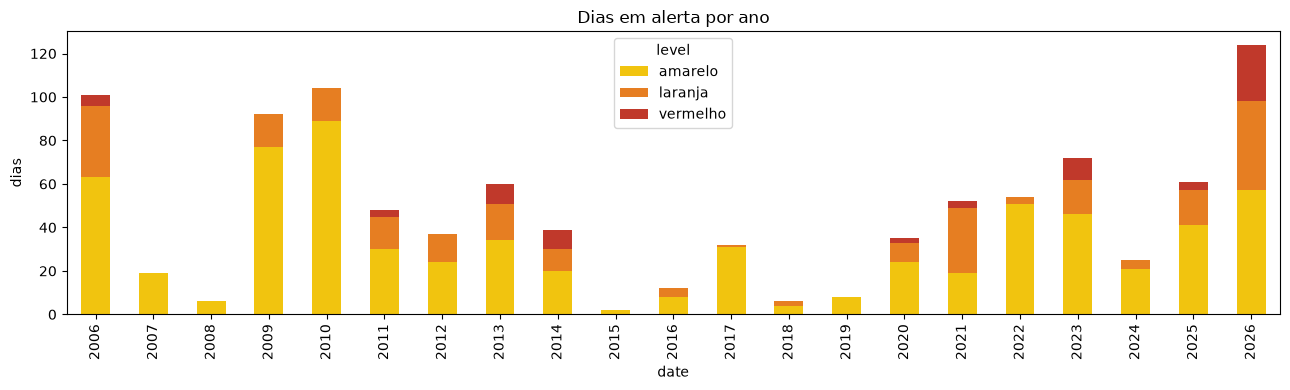

In [3]:
daily = alerts.daily_alerts(cfg)
daily.to_csv(drivers.table(cfg, "alertas_diarios"))
dias = daily.groupby(daily.index.year)["level"].value_counts().unstack(fill_value=0).rename(columns=alerts.LEVELS)
ax = dias[["amarelo", "laranja", "vermelho"]].plot.bar(stacked=True, figsize=(13, 4), color=["#f1c40f", "#e67e22", "#c0392b"],
                                                      title="Dias em alerta por ano", ylabel="dias")
plt.tight_layout(); plt.savefig(REPORTS / "32_dias_em_alerta_por_ano.png", dpi=110)
daily["alerta"].value_counts().to_frame("dias em 20 anos")

## 3. Um episódio visto de perto: a cheia de janeiro de 2026

As linhas verticais marcam as datas em que o Copernicus mapeou a cheia em
Marracuene (17 e 24 de janeiro).

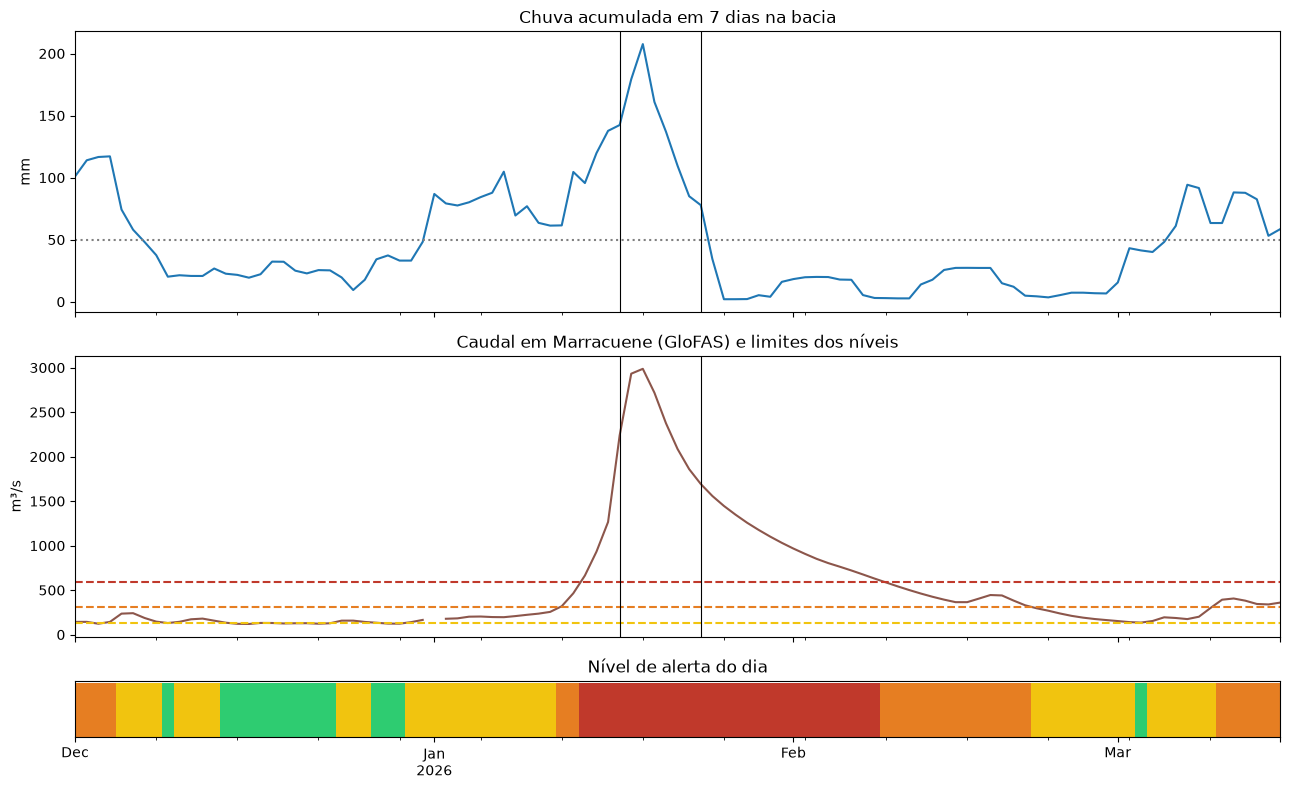

In [4]:
window = daily.loc["2025-12-01":"2026-03-15"]
colours = {0: "#2ecc71", 1: "#f1c40f", 2: "#e67e22", 3: "#c0392b"}
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, height_ratios=[3, 3, 0.6])
window["p7_basin"].plot(ax=axes[0], color="tab:blue"); axes[0].axhline(limits["rain_p7_min_mm"], color="grey", linestyle=":")
axes[0].set_ylabel("mm"); axes[0].set_title("Chuva acumulada em 7 dias na bacia")
window["discharge_m3s"].plot(ax=axes[1], color="tab:brown")
for name, value in limits["discharge_m3s"].items():
    axes[1].axhline(value, color={"amarelo": "#f1c40f", "laranja": "#e67e22", "vermelho": "#c0392b"}[name], linestyle="--")
axes[1].set_ylabel("m³/s"); axes[1].set_title("Caudal em Marracuene (GloFAS) e limites dos níveis")
axes[2].bar(window.index, 1, width=1, color=[colours[v] for v in window["level"]]); axes[2].set_yticks([]); axes[2].set_title("Nível de alerta do dia")
for ax in axes[:2]:
    for day in ["2026-01-17", "2026-01-24"]:
        ax.axvline(pd.Timestamp(day), color="black", linewidth=0.8)
plt.tight_layout(); plt.savefig(REPORTS / "32_alerta_janeiro_2026.png", dpi=110)

## 4. Teriam as regras avisado a tempo?

In [5]:
events = {
    "jan 2026: primeira cheia mapeada em Marracuene (Copernicus)": "2026-01-17",
    "jan 2026: maior extensão mapeada (Copernicus)": "2026-01-24",
    "fev 2023: ativação do Copernicus para a província de Maputo": "2023-02-11",
}
antecedencia = pd.DataFrame({name: alerts.lead_time(daily, day) for name, day in events.items()}).T
antecedencia.to_csv(REPORTS / "32_antecedencia_dos_alertas.csv")
antecedencia

,primeiro_alerta,dias_de_antecedencia,nivel_no_dia
jan 2026: primeira cheia mapeada em Marracuene (Copernicus),2026-01-12,5,vermelho
jan 2026: maior extensão mapeada (Copernicus),2026-01-12,12,vermelho
fev 2023: ativação do Copernicus para a província de Maputo,2023-02-10,1,vermelho


`dias_de_antecedencia` conta os dias entre o primeiro alerta laranja ou vermelho
e a data do evento. Os dois eventos são posteriores a 2021, por isso não
influenciaram os limites.

## 5. Todos os episódios de alerta laranja ou vermelho

In [6]:
ep = alerts.episodes(daily)
ep.to_csv(REPORTS / "32_episodios_de_alerta.csv", index=False)
print(f"{len(ep)} episódios em 20 anos, {int((ep['nivel_maximo'] == 'vermelho').sum())} chegaram a vermelho")
ep[ep["nivel_maximo"] == "vermelho"]

34 episódios em 20 anos, 10 chegaram a vermelho


,inicio,fim,dias_em_alerta,nivel_maximo,chuva_7d_max_mm,caudal_max_m3s,primeiro_gatilho
1,2006-03-02,2006-04-06,33,vermelho,102.000,623.000,caudal
8,2011-01-17,2011-02-03,18,vermelho,61.000,684.000,caudal
12,2013-01-20,2013-02-12,24,vermelho,154.000,"1,961.000",chuva
14,2014-03-06,2014-03-23,18,vermelho,148.000,728.000,chuva
18,2020-01-21,2020-01-23,3,vermelho,54.000,635.000,caudal
19,2020-02-12,2020-02-15,4,vermelho,93.000,646.000,caudal
22,2021-01-27,2021-03-02,33,vermelho,152.000,"1,230.000",caudal
24,2023-02-10,2023-03-05,24,vermelho,244.000,"2,371.000",chuva
29,2025-01-14,2025-01-22,9,vermelho,77.000,809.000,caudal
32,2026-01-12,2026-02-21,41,vermelho,208.000,"2,987.000",caudal


## 6. Os alertas coincidem com a água vista por satélite?

Para cada mês desde 2015: o nível de alerta mais alto do mês e a área de cheia
medida pelo Modelo B. Se os gatilhos fazem sentido, os meses em vermelho devem
ter mais água.

,meses,cheia mediana no distrito (km²),cheia máxima (km²)
alerta,,,
verde,85,31.500,64.400
amarelo,20,31.500,43.700
laranja,17,34.700,133.800
vermelho,7,39.800,215.300


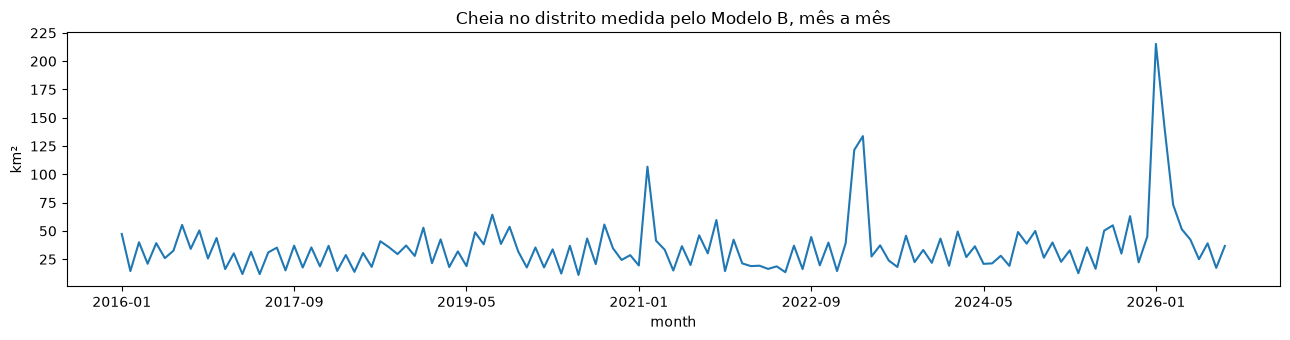

In [7]:
area_file = drivers.table(cfg, "modelo_b_area_mensal")
if area_file.exists():
    area = pd.read_csv(area_file, index_col=0)
    # 2015 fica de fora: só tem uma órbita de radar (ângulo diferente), o modelo não foi treinado
    # com esse ano e os seus mapas dão água a mais
    area = area[area.index >= f"{P['model_b_start_year']}-01"]
    monthly_level = daily["level"].resample("MS").max()
    monthly_level.index = monthly_level.index.strftime("%Y-%m")
    both = area.join(monthly_level.rename("nivel")).dropna()
    both["alerta"] = both["nivel"].map(alerts.LEVELS)
    resumo = both.groupby("alerta")["cheia_distrito_km2"].agg(["count", "median", "max"]).reindex(["verde", "amarelo", "laranja", "vermelho"])
    resumo.columns = ["meses", "cheia mediana no distrito (km²)", "cheia máxima (km²)"]
    resumo.round(1).to_csv(REPORTS / "32_alerta_vs_agua_por_satelite.csv")
    ax = both["cheia_distrito_km2"].plot(figsize=(13, 3.5), color="tab:blue", ylabel="km²", title="Cheia no distrito medida pelo Modelo B, mês a mês")
    plt.tight_layout(); plt.savefig(REPORTS / "32_cheia_mensal_modelo_b.png", dpi=110)
    display(resumo.round(1))
else:
    print("correr primeiro: .venv/bin/python scripts/run_model_b_maps.py (mapas mensais do Modelo B)")

**Leitura honesta.** A relação existe mas é fraca: a cheia máxima é claramente
maior nos meses em vermelho, mas a mediana pouco muda de nível para nível. Há
duas razões. Primeiro, o Modelo B tem um nível de fundo de algumas dezenas de
km² (zonas húmidas que o radar vê escuras), que está presente em todos os meses.
Segundo, o alerta mede a **causa** (chuva e caudal na bacia) e o satélite mede o
**efeito** no distrito, que pode chegar dias ou semanas depois e cair no mês
seguinte. Os gatilhos servem para avisar; o mapa de satélite serve para
confirmar onde a água chegou. Um não substitui o outro.

## 7. Onde e quem: exposição por classe de suscetibilidade

Dentro do distrito de Marracuene. As colunas "em zona alagada" contam o que
ficou dentro da cheia de janeiro de 2026 mapeada pelo Copernicus.

In [8]:
flooded_2026 = M.reference_raster(cfg, "2026-01", res=30) == 2
exposure = alerts.exposure_by_class(cfg, flooded=flooded_2026)
exposure.round(1).to_csv(REPORTS / "32_exposicao_por_classe.csv")
exposure.round(1)

,area_km2,area_alagada_km2,edificios,edificios_em_zona_alagada,escolas,escolas_em_zona_alagada,unidades_de_saude,unidades_de_saude_em_zona_alagada
suscetibilidade,,,,,,,,
baixa,282.300,0.200,148391,14,12,0,12,0
média,233.500,82.400,52336,299,2,0,3,0
alta,122.800,103.800,505,56,0,0,0,0
muito alta,39.700,27.700,70,11,0,0,0,0


**Como usar esta tabela num alerta.** Quando os gatilhos passam a laranja ou
vermelho, as zonas a avisar primeiro são as de classe **alta** e **muito alta**;
a tabela diz quantos edifícios lá estão.

## Limites do motor de alertas

- **O caudal usado aqui é uma reanálise.** O GloFAS histórico é publicado com
  atraso. Em operação, o gatilho de caudal tem de usar a **previsão** do GloFAS
  (até 30 dias) e a chuva tem de vir do IMERG, que é quase em tempo real. A
  ligação a essas fontes é trabalho da Semana 4.
- **Não há lista oficial de cheias para contar falsos alarmes.** Sabe-se que os
  maiores episódios coincidem com cheias conhecidas; para os mais pequenos não
  há como confirmar se houve água.
- **Dois eventos de teste** posteriores a 2021. É pouco para garantir uma
  antecedência.
- **A contagem de edifícios vem do Google Open Buildings** e a de escolas e
  unidades de saúde do OpenStreetMap, que é incompleto nas zonas rurais: são
  valores mínimos.
- **O alerta é para a bacia e o distrito inteiros**, não bairro a bairro.